# HinglishSense: end-to-end walkthrough

Sentiment analysis (positive / negative / neutral) of Hindi-English code-mixed text.

This notebook runs the whole pipeline on the processed data, step by step:

1. Load the data
2. Hinglish preprocessing
3. TF-IDF word + character features
4. Train the three models and tune them on the validation set
5. Evaluate on the test set
6. Interpret the model and look at errors
7. Predict new sentences

> Run `python -m src.data_loader` once before this notebook, so that `data/processed/` exists.

In [1]:
import sys
from pathlib import Path

# The notebook lives in notebooks/, the code in src/ -> add the project folder to the path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import config
pd.set_option("display.max_colwidth", 120)

## 1. Load the data

Three CSV files with two columns, `text` and `label`, made by `src/data_loader.py` from the SentiMix (SemEval-2020 Task 9) Hinglish tweets.

In [2]:
train_df = pd.read_csv(config.TRAIN_PATH, keep_default_na=False)
val_df = pd.read_csv(config.VAL_PATH, keep_default_na=False)
test_df = pd.read_csv(config.TEST_PATH, keep_default_na=False)

sizes = pd.DataFrame({name: df["label"].value_counts() for name, df in
                      [("train", train_df), ("validation", val_df), ("test", test_df)]})
sizes.loc["total"] = sizes.sum()
sizes

,train,validation,test
label,,,
neutral,5148,1103,1103
positive,4554,976,976
negative,4070,872,873
total,13772,2951,2952


In [3]:
train_df.sample(8, random_state=1)

,text,label
4270,RT I'm a visual artist . This is one of my recent works . I'm new on Twitter . Show me around 😊 Please help RT !,neutral
12231,Bsdk Haan desh mein 3 crore Bangladeshi aur Rohingya bhi inhi log leke aaye hai desh ki …,negative
4089,I WISH VERY EXTREMELY HAPPY AND #BLESSED #RAMADAN OR #RAMJAAN MONTH TO YOU THE WOW AND HOW POWERFUL CELEBRITY KATRI …,positive
6054,Thank you Feyn ! I love shading hair the most ; v ;)/♥,positive
10111,RT Your heart will kill you faster than the bullet,neutral
3716,RT_dvn KALANK in theatres now #Zafar aap ka hain A character I loved playing in this epic love story No spoilers please,positive
12857,RT BJP leader Vishwas Sarang in Bhopal Tabaadla udyog Congress ki sarkar mein phal raha hai vidhayak is vyapar ke ke...,neutral
13536,Pahle pucho Wah kya chahta h agar Wah love karta h ya t …,neutral


## 2. Hinglish preprocessing

`clean_text()` lowercases the text, removes URLs and mentions, turns emojis into words, shortens elongations (*mastttt*) and normalizes spellings with `data/normalization_map.csv` (*bohot → bahut*, *nhi → nahi*).

In [4]:
from src.preprocess import clean_text

examples = [
    "Movie ekdum mastttt thi 😍😍 but climax thoda boring tha!!!",
    "Bohot bakwaas film yaar, paisa waste 👎 https://t.co/abc @friend",
    "Khana acha nhi tha, plz mat jaana #disappointed",
]
for sentence in examples:
    print("RAW    :", sentence)
    print("CLEANED:", clean_text(sentence))
    print()

RAW    : Movie ekdum mastttt thi 😍😍 but climax thoda boring tha!!!
CLEANED: movie ekdum mast thi emoji_smiling_face_with_heart_eyes emoji_smiling_face_with_heart_eyes but climax thoda boring tha !! emo_pos emo_pos

RAW    : Bohot bakwaas film yaar, paisa waste 👎 https://t.co/abc @friend
CLEANED: bahut bakwas film yaar , paisa waste emoji_thumbs_down emo_neg

RAW    : Khana acha nhi tha, plz mat jaana #disappointed
CLEANED: khana accha nahi tha , please mat jaana disappointed



In [5]:
normalization_map = pd.read_csv(config.NORMALIZATION_MAP_PATH)
print(len(normalization_map), "spelling variants, for example:")
normalization_map.sample(10, random_state=3)

363 spelling variants, for example:


,variant,canonical
102,gai,gayi
328,cuz,because
199,thik,theek
24,bauhat,bahut
134,abhii,abhi
159,pagl,pagal
151,blkl,bilkul
112,ku,ko
332,tmrw,tomorrow
153,kush,khush


## 3. TF-IDF features: word n-grams + character n-grams

Character n-grams make *acha*, *accha* and *achha* look similar to the model, even if the map misses a spelling.

In [6]:
from src.features import build_features

train_clean = [clean_text(text) for text in train_df["text"]]
val_clean = [clean_text(text) for text in val_df["text"]]

vectorizer = build_features("both")
X_train = vectorizer.fit_transform(train_clean)
X_val = vectorizer.transform(val_clean)
print("Feature matrix:", X_train.shape, "(tweets x features)")

Feature matrix: (13772, 107656) (tweets x features)


## 4. Train three models and tune them on the validation set

We only look at **validation** scores here. The test set is kept for the end.

In [7]:
from src.train_baselines import MODEL_NAMES, make_model, param_grid, macro_f1

rows = []
for name in MODEL_NAMES:
    for param in param_grid(name):
        model = make_model(name, param).fit(X_train, train_df["label"])
        score = macro_f1(val_df["label"], model.predict(X_val))
        rows.append({"model": name, "param (alpha or C)": param, "val macro-F1": round(score, 4)})
tuning = pd.DataFrame(rows)
tuning

,model,param (alpha or C),val macro-F1
0,naive_bayes,0.1,0.6049
1,naive_bayes,0.5,0.6013
2,naive_bayes,1.0,0.6056
3,logistic_regression,0.1,0.6249
4,logistic_regression,1.0,0.6388
5,logistic_regression,10.0,0.6184
6,linear_svm,0.1,0.6396
7,linear_svm,1.0,0.6135
8,linear_svm,10.0,0.5905


In [8]:
best_per_model = tuning.loc[tuning.groupby("model")["val macro-F1"].idxmax()]
best_per_model

,model,param (alpha or C),val macro-F1
6,linear_svm,0.1,0.6396
4,logistic_regression,1.0,0.6388
2,naive_bayes,1.0,0.6056


## 5. Evaluate on the test set

We build each best model as a full `Pipeline` (cleaner → TF-IDF → classifier), train it on the training set, and score it **once** on the test set.

In [9]:
from sklearn.metrics import accuracy_score, classification_report, f1_score
from src.train_baselines import build_pipeline

setup = {"features": "both", "use_normalization": True, "negation_scope": None}
pipelines, results = {}, []
for _, row in best_per_model.iterrows():
    pipeline = build_pipeline(row["model"], row["param (alpha or C)"], setup)
    pipeline.fit(list(train_df["text"]), list(train_df["label"]))
    predictions = pipeline.predict(list(test_df["text"]))
    pipelines[row["model"]] = pipeline
    results.append({"model": row["model"],
                    "test accuracy": round(accuracy_score(test_df["label"], predictions), 4),
                    "test macro-F1": round(f1_score(test_df["label"], predictions, average="macro"), 4)})
pd.DataFrame(results).sort_values("test macro-F1", ascending=False)

,model,test accuracy,test macro-F1
0,linear_svm,0.6365,0.6403
1,logistic_regression,0.6264,0.6294
2,naive_bayes,0.6186,0.6217


In [10]:
svm_predictions = pipelines["linear_svm"].predict(list(test_df["text"]))
print(classification_report(test_df["label"], svm_predictions, digits=3))

              precision    recall  f1-score   support

    negative      0.660     0.674     0.667       873
     neutral      0.570     0.560     0.565      1103
    positive      0.689     0.690     0.689       976

    accuracy                          0.637      2952
   macro avg      0.640     0.641     0.640      2952
weighted avg      0.636     0.637     0.636      2952



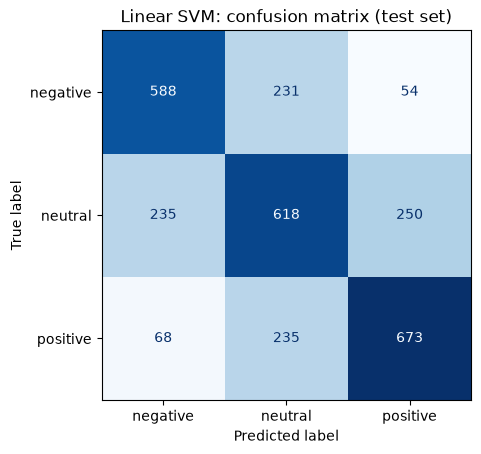

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(test_df["label"], svm_predictions,
                                        labels=config.LABELS, cmap="Blues", colorbar=False)
plt.title("Linear SVM: confusion matrix (test set)")
plt.show()

**Reading the matrix:** positive and negative are rarely swapped. Most mistakes involve the *neutral* class.

## 6. Interpretation and errors

The Logistic Regression weights tell us which words and character n-grams push a tweet towards positive or negative.

In [12]:
from src.evaluate import lr_polarity_scores

scores = lr_polarity_scores(pipelines["logistic_regression"]).sort_values()
print("Most NEGATIVE features:", list(scores.head(15).index))
print()
print("Most POSITIVE features:", list(scores.tail(15).index[::-1]))

Most NEGATIVE features: ['bc', 'shame', 'fuck', 'tu', 'baap', 'chor', 'saale', 'nahi', "'_bc' (char)", 'fake', "'kut' (char)", 'teri', "'_bc_' (char)", "'_ch' (char)", "'_kut' (char)"]

Most POSITIVE features: ['good', 'love', 'great', 'ji', 'proud', 'bahut', 'badhai', 'best', 'dil', 'bhai', 'the best', 'very', 'and', 'e', 'congratulations']


In [13]:
test_with_predictions = test_df.assign(predicted=svm_predictions)
mistakes = test_with_predictions[test_with_predictions["label"] != test_with_predictions["predicted"]]
print(f"{len(mistakes)} of {len(test_df)} test tweets misclassified")
mistakes.sample(8, random_state=7)

1073 of 2952 test tweets misclassified


,text,label,predicted
1901,mulk mei log khush hain .. tumhe sab acchi bato mei sirf buri nazar aay …,negative,positive
1389,Kya bakchodi hai flop actor ko Batman bana diya isska haal Ben Affleck se ghatiya hoga,neutral,negative
583,Bijli ki halat mai koi sudhaar nahi #Jhansi ki bijli ki halat bahut kharab raat din bijli gayab Sar …,negative,neutral
2055,RT_Yogi Dear Indian Muslims I know that u feel like giving up on Indian politics but remember just becoz u won …,negative,neutral
1432,😁 Mai ne b unfollow kar diya return . Jiska shoutout yeh thread Mai Kiya tumne 😬😬,positive,neutral
1027,Bahut zyaada yaar . Log kitnay ganday aur zaalim hain . Doosron ki betiyon ki zindagiyan ujaartay hain i …,positive,negative
88,Vo kainat ke pass nahi jaega but Saltanat dusre ke pass jaegi zaroon is looking so hurt n angry,positive,neutral
2708,Unused EVM machines hain uncle Ab inme chah ke bhi vote nahi dal sakte 5 saal pehle hall …,neutral,negative


In [14]:
ablation = pd.read_csv(config.ABLATION_PATH)
ablation[["variant", "val_macro_f1", "test_macro_f1"]]

,variant,val_macro_f1,test_macro_f1
0,word only,0.6236,0.6149
1,"word only, no normalization",0.6227,0.6120
2,char only,0.6376,0.6357
3,word + char,0.6388,0.6294
4,"word + char, no normalization",0.6372,0.6278
5,word + char + NEG_ (after negator),0.6363,0.6312
6,word + char + NEG_ (both sides),0.6347,0.6323


The ablation table (made by `python -m src.train_baselines`) shows that character n-grams give the largest improvement.

## 7. Predict new sentences

`predict_sentiment()` uses the saved best model (`models/best_baseline.joblib`).

In [15]:
from src.predict import predict_sentiment

for sentence in ["movie bahut mast thi", "ekdum bakwas film, paisa waste",
                 "kal college mein exam hai", "India ne match jeet liya 😍🔥",
                 "khana accha nahi tha"]:
    result = predict_sentiment(sentence)
    print(f"{result['label']:<9} {result['confidence']:.2f}  {sentence}")

positive  0.60  movie bahut mast thi
negative  0.67  ekdum bakwas film, paisa waste
neutral   0.75  kal college mein exam hai
positive  0.64  India ne match jeet liya 😍🔥
neutral   0.63  khana accha nahi tha


Note the last sentence: negation (*accha nahi*) is still hard for a bag-of-n-grams model, which is one of the limitations discussed in the report.